NAME : CATHERINE JOSEPH

REG NO: 240242457000

CLASS: BENG24COE-3

TASK 1.1

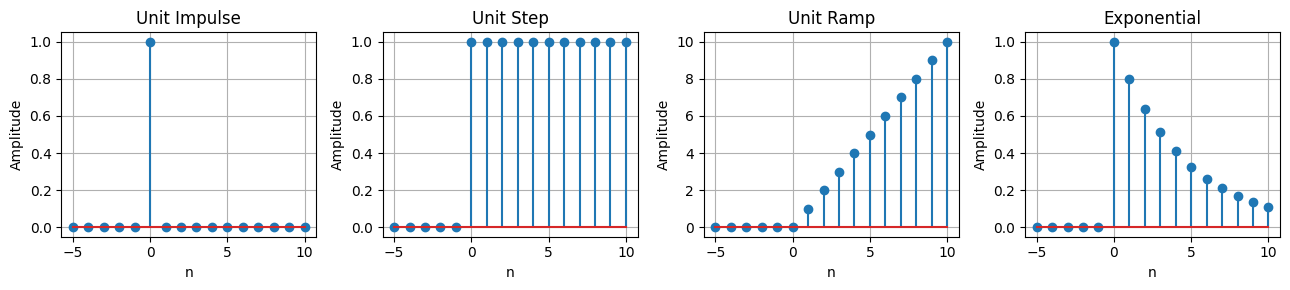

In [ ]:

# Generate the discrete-time index
n = np.arange(-5, 11)

# Unit impulse
delta = (n == 0).astype(float)

# Unit step
step = (n >= 0).astype(float)

# Unit ramp
ramp = n * step

# Exponential signal
expo = 0.8**n * step

# Plot the four signals
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit Impulse", "Unit Step", "Unit Ramp", "Exponential"]
):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()


TASK 1.2 a) exponential signals

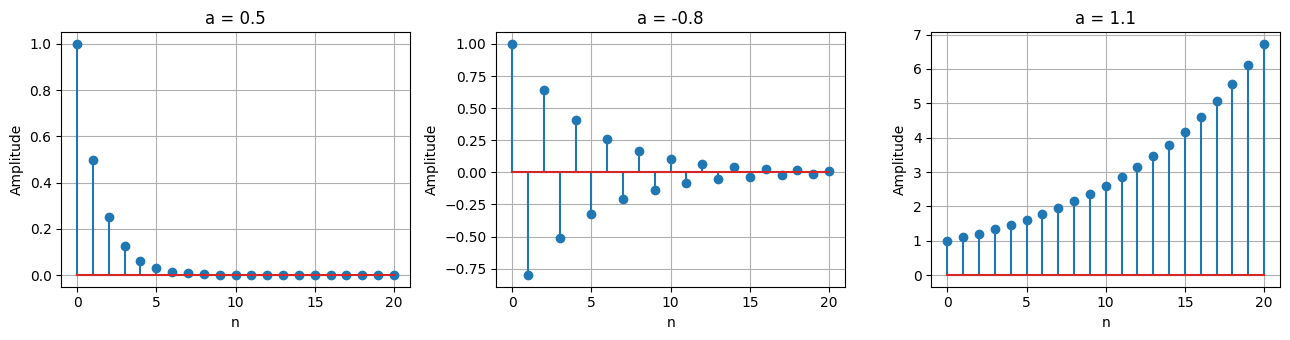

In [ ]:

n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = (a**n) * (n >= 0)

    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()


Task 1.2 b)

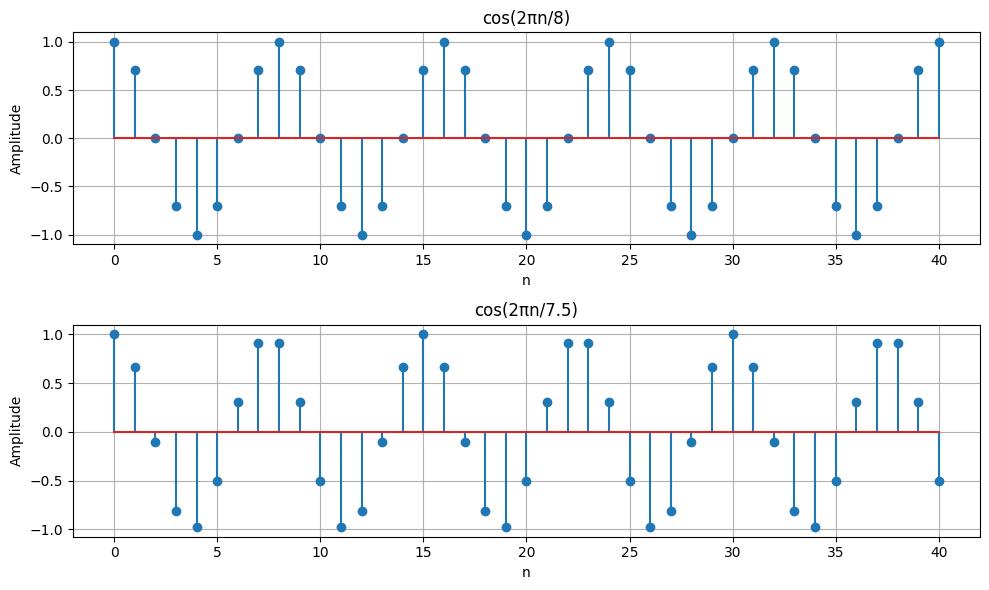

In [ ]:

n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].stem(n, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()


The signal \(\cos(2\pi n/8)\) repeats exactly because its period is 8 samples, which is an integer.

The signal \(\cos(2 n/7.5)\) does not repeat exactly at integer sample positions because its period is 7.5 samples, which is not an integer.

Task 1.3

Sampling rate: 48000 Hz
Duration: 3.73 seconds
Total samples: 179200


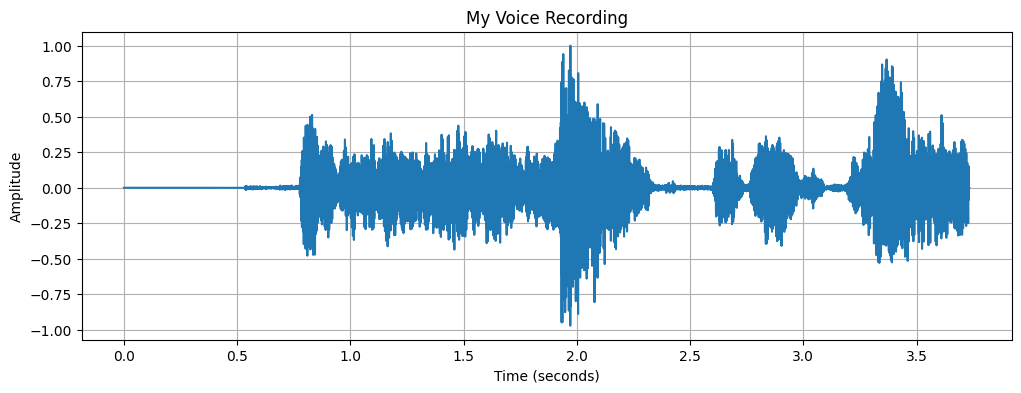

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
import os

# Convert the .m4a file to a .wav file using ffmpeg
!ffmpeg -i my_voice.wav.m4a my_voice.wav -y -loglevel quiet

fname = "my_voice.wav"

try:
    # Read the converted audio file
    fs, x = wavfile.read(fname)

    # Convert stereo recording to mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Normalize the audio safely
    x = x.astype(float)
    if np.max(np.abs(x)) > 0:
        x = x / np.max(np.abs(x))

    # Calculate time and recording duration
    t = np.arange(len(x)) / fs

    print("Sampling rate:", fs, "Hz")
    print("Duration:", round(len(x) / fs, 2), "seconds")
    print("Total samples:", len(x))

    # Plot the voice recording
    plt.figure(figsize=(12, 4))
    plt.plot(t, x)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title("My Voice Recording")
    plt.grid()
    plt.show()

    # Play your own voice
    display(Audio(x, rate=fs))
except Exception as e:
    print(f"Error reading the file: {e}")

## ANALYSIS QUESTIONS

**Question 1: What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?**

**Answer:**

The sampling rate is the number of samples recorded per second, measured in Hertz (Hz). The sampling rate of my recording is obtained from the Python program.

The number of samples needed to store one minute of mono audio is calculated using:

\[
N=f_s\times60
\]

Where:
- N = Total number of samples.
- \(f_s\) = Sampling rate.

For example, if the sampling rate is 16,000 Hz:

\[
N=16000\times60=960,000
\]

Therefore, 960,000 samples are required to store one minute of mono audio at 16,000 Hz.

**Question 2: Why is a stem plot more appropriate than a continuous line for x(n)?**

**Answer:**

A stem plot is more appropriate for representing a discrete-time signal because discrete-time signals are defined only at separate integer sample positions. It displays individual sample values clearly and shows that there are no signal values between the samples. A continuous line graph may incorrectly suggest that the signal exists at every point in time.

**Question 3: For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response?**

**Answer:**

It would violate the Bounded-Input Bounded-Output (BIBO) stability property. A stable system must produce a bounded output for every bounded input. If an impulse response grows continuously, its absolute sum does not converge. Therefore, the system would be unstable.

## AI-USE STATEMENT

**AI tools used:** ChatGPT.

**Used for:** ChatGPT was used to help explain Digital Signal Processing concepts, understand the laboratory instructions, provide guidance on Python programming and assist in understanding errors encountered during the laboratory activities.

**How I verified the output:** I verified the output by running the Python code in Google Colab, checking the generated signal graphs and comparing the results with the expected behaviour of the signals. I also tested the audio recording by playing it back.

I confirm that I understand and can explain all submitted code.
